# Introducción:

En este trabajo se utilizará una base de datos sintética extraída de [Kaggle](https://www.kaggle.com/), que contiene información sobre intentos de ciberataques a empresas. Con ella intentaremos conocer y analizar estos ataques; como y donde se llevan a cabo, que particularidades tienen, que patrones existen, entre otras cosas. Y también observar el hecho desde el lugar de la víctima, sus posibles reacciones y sus consecuencias. 

Para ello, se aplicarán medidas de resumen, tablas, gráficos, y entrenaremos algunos modelos de machine learning para predecir diferentes aspectos de estos ataques.

Si bien la ciberseguridad es un tema muy importante, el cual se debe conocer y enfatizar para evitar posibles graves consecuencias, que lo convierte en un tema muy interesante para investigar; el objetivo principal de este trabajo es explorar, analizar datos, aplicar técnicas estadísticas, no sacar conclusiones sobre la ciberseguridad real.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Enterprise_Cyber_Kill_Chain_Dataset.csv")

# Datos:

Como se mencionó en la introducción, el dataset fue creado artificialmente de manera realista, sin ningún tipo de información personal.

Cada fila refiere a un intento de ciberataque diferente, del cual se contiene toda la información, desde el primer momento en que se intenta hasta las consecuencias finales en la víctima.

Columnas: Podemos agrupar las columnas del dataset de la siguiente manera

| Grupo | Variables |
|---|---|
| Identificación y fecha | `Incident_ID`, `Timestamp`, `Hour`, `DayOfWeek`, `Month`, `Business_Hours`, `Weekend` |
| Características de la Empresa | `Industry`, `Country`, `Company_Size`, `Employee_Count`, `Compliance`, `Vendor_Count`, `SOC_Team_Size` |
| Seguridad ante ataques | `Firewall`, `MFA`, `EDR`, `IDS`, `Security_Training`, `Password_Policy`, `Security_Maturity`, `Security_Audit_Score` |
| Posibles vulnerabilidades | `Patch_Age_Days`, `Open_Vulnerabilities`, `CVSS_Score`, `Internet_Exposed`, `ThirdParty_Risk`, `Insider_Risk` |
| Comienzo del ataque | `Attack_Vector`, `Threat_Actor`, `Attack_Complexity`, `Zero_Day`, `Phishing_Click` |
| Progresión del ataque | `Credential_Stolen`, `Privilege_Escalation`, `Lateral_Movement`, `Persistence`, `Data_Encrypted`, `Attack_Stage` |
| Consecuencias | `Data_Exfiltration_GB`, `Detection_Time_Min`, `Response_Time_Min`, `Downtime_Hours`, `Records_Compromised`, `Financial_Loss_USD`, `Recovery_Cost_USD` |
| Resultado  | `Attack_Success`, `Cyber_Risk_Score`, `Risk_Level`, `Incident_Severity` |


## Principal información del dataframe:

In [2]:
print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])
print("Tipos de columnas:")
print(df.dtypes.value_counts().to_string())
print("Cantidad de ataques ('Incident_ID'):", df["Incident_ID"].nunique())

Filas: 100500
Columnas: 50
Tipos de columnas:
int64      25
str        14
float64    11
Cantidad de ataques ('Incident_ID'): 100000


Vemos que el dataframe tiene 100500 filas pero 100000 `Indicent_ID` de ataques distintos, es decir, contiene 500 filas duplicadas.

Las eliminamos y contamos nuevamente:

In [3]:
df = df.drop_duplicates()

print("Filas:", df.shape[0])
print("Cantidad de ataques ('Incident_ID'):", df["Incident_ID"].nunique())


Filas: 100000
Cantidad de ataques ('Incident_ID'): 100000


In [4]:
print("Cantidad de datos faltantes por columna:")
print(df.isna().sum().sort_values(ascending = False).head(6).to_string())
print("...                       0")


Cantidad de datos faltantes por columna:
Recovery_Cost_USD     70594
Compliance            42772
Financial_Loss_USD     5006
Detection_Time_Min     3147
Company_Size              0
Employee_Count            0
...                       0


Entonces tenemos una base de datos con 100000 ataques diferentes y 50 variables que caracterizan cada uno de ellos. De estas 50, tenemos 25 númericas discretas (int64), 11 continuas (float64) y 14 cualitativas (str). Debemos tener en cuenta que algunas de las 25 discretas, son binarias, que valen 1 si la observación cumple con esa variable, y 0 en caso contrario. Además, solamente cuatro columnas tienen datos faltantes. Trataremos con ellos al momento de utilizar dichas columnas.

Las variables de respuesta o interés de este analisis son: 

- `Attack_Success` que indica si el ataque tuvo éxito (1) o no (0)

- `Cyber_Risk_Score` que numera del 1 al 100 cada ataque según su nivel de riesgo.

## Distribución de variables de interés

### Frecuencia de `Attack_Succes`:

In [5]:
df["Attack_Success"].value_counts()

Attack_Success
0    70594
1    29406
Name: count, dtype: int64

<positron-console-cell-6>:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.


Text(0, 0.5, 'Cantidad de ataques')

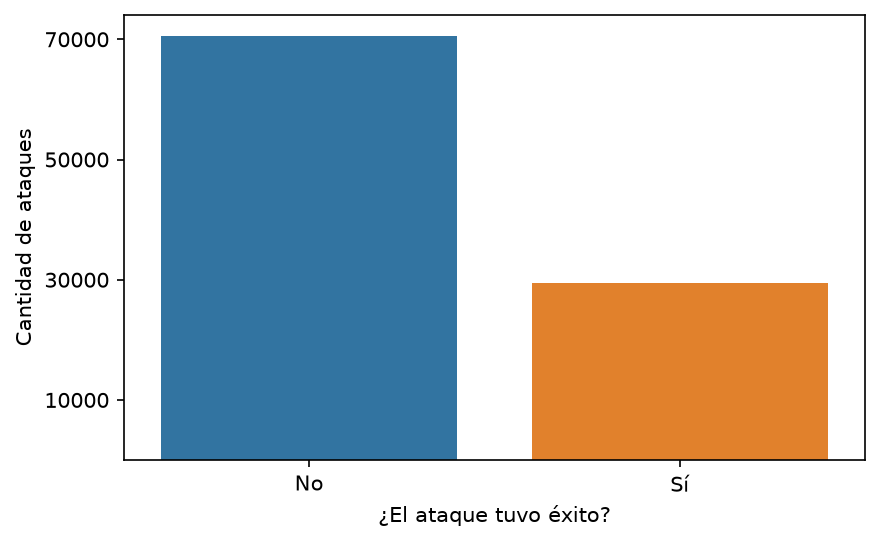

In [6]:
fig, ax = plt.subplots(figsize=(5.75, 3.5), layout="constrained")
sns.countplot(data = df, x = "Attack_Success", hue = "Attack_Success", ax=ax)
ax.legend().remove()
ax.set_xticklabels(["No", "Sí"])
ax.set_yticks([10000,30000,50000,70000])
ax.set_xlabel("¿El ataque tuvo éxito?")
ax.set_ylabel("Cantidad de ataques")



Vemos que de los 100000 ataques, 70594, fracasó y los 29406 casos restantes efectivamente tuvieron éxito.

El gráfico de barras nos permite visualizar la gran diferencia en las frecuencias, habiendo más del doble de observaciones de una categoría con respecto a la otra. Evidencia un dataset desbalanceado.

### Distribución `Cyber_Risk_Score`:

In [7]:
df["Cyber_Risk_Score"].describe()

count    100000.000000
mean         45.005120
std          19.047731
min           1.337935
25%          30.387444
50%          41.635008
75%          57.437351
max         100.000000
Name: Cyber_Risk_Score, dtype: float64

Text(0, 0.5, 'Cantidad')

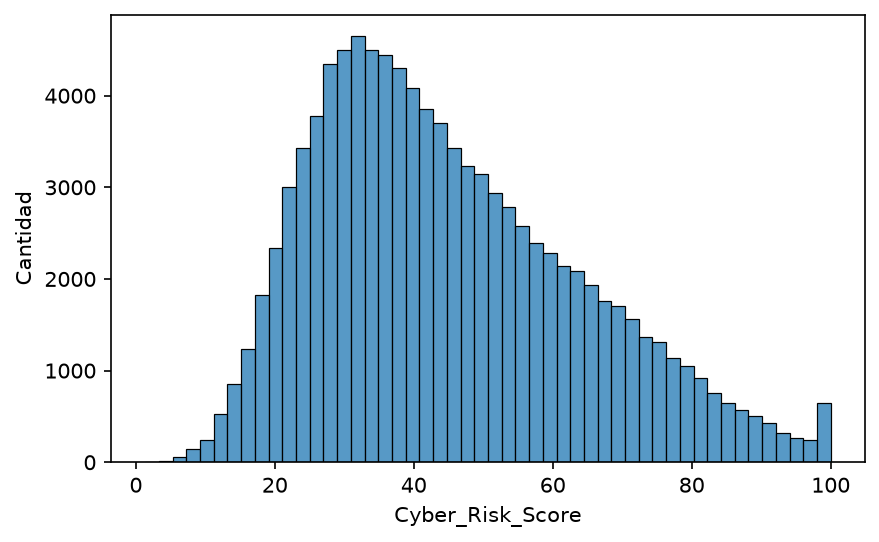

In [8]:
fig, ax = plt.subplots(figsize=(5.75, 3.5), layout="constrained")
sns.histplot(data=df, x="Cyber_Risk_Score", ax=ax, fill = True, bins = 50)
ax.set_ylabel("Cantidad")


El nivel de riesgo del ataque observamos que tiene una distribución, con media 45 y mediana 41.6, asimétrica a la derecha, donde además el tercer percentil es 57.4 y el máximo 100. La gran concentración de los datos lo vemos en el pico de la curva entre 25 y 45 de puntaje de riesgo.

También se destaca el último intevalo que rompe con el patrón decreciente, acumulando gran número de observaciones con respecto a los intervalos anteriores.

<Axes: xlabel='Cyber_Risk_Score', ylabel='Density'>

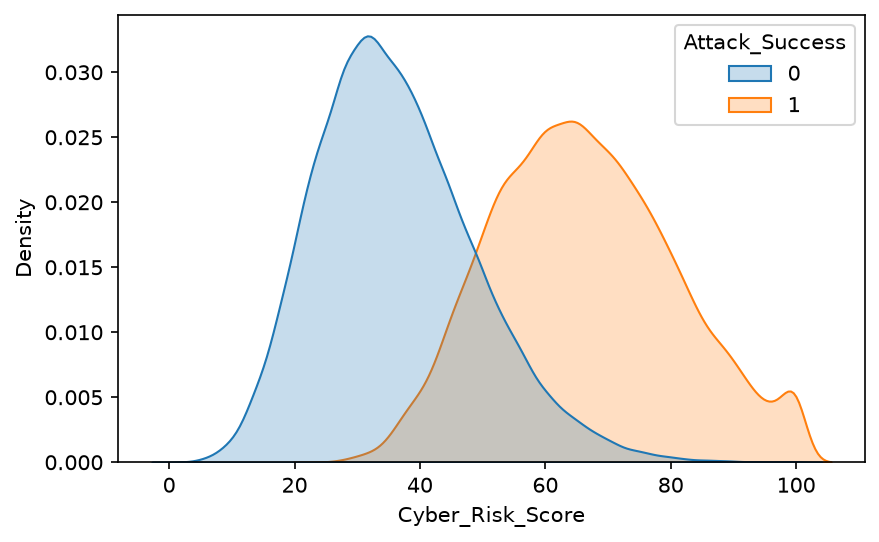

In [9]:
fig, ax = plt.subplots(figsize=(5.75, 3.5), layout="constrained")
sns.kdeplot(data=df,
 x = "Cyber_Risk_Score",
 hue = "Attack_Success",
ax=ax, fill = True, common_norm = False)



En el gráfico de densidad, separado por éxito del ataque, vemos que las dos distribuciones son claramente distintas: los ataques fallidos se concentran alrededor de 30-35 puntos, mientras que los exitosos lo hacen alrededor de 65. Aunque se ve una zona de solapamiento entre los 40 y 60 puntos, demuestra que hay una correlación fuerte entre ambas variables.

# Análisis exploratorio

En este apartado intentaremos analizar y encontrar relaciones entre variables, y en especial su comportamiento con respecto a nuestras variables de interés. 

La elección de ellas es por simple sospecha o suposición de que pueden tener una relación interesante para visualizar.

Cada análisis se hace a través de una tabla o gráfica, que intenta responder una pregunta disparadora.

### ¿Un ataque que tuvo éxito fue más díficil de detectar?

[Text(0.5, 0, 'Tiempo en detectar al ataque (min)')]

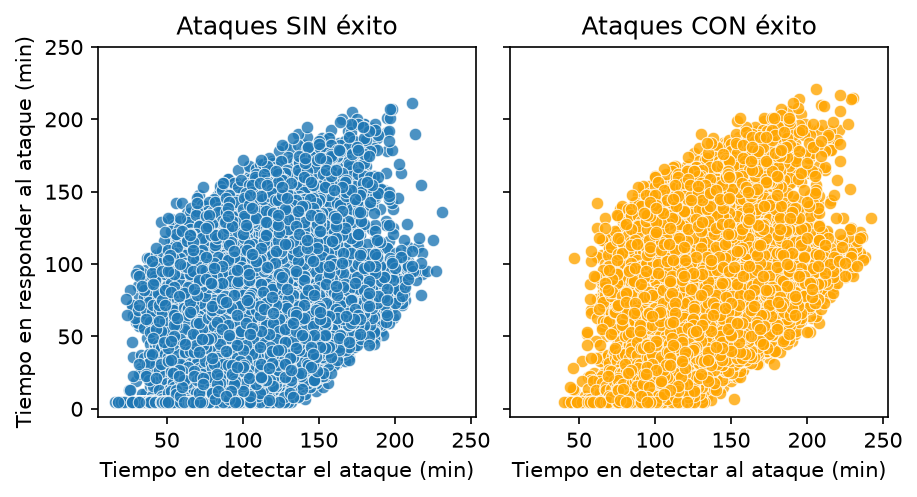

In [10]:
fig, axes = plt.subplots(1,2,figsize=(6, 3.2), layout="constrained", sharex=True, sharey=True)

sns.scatterplot(data = df[df["Attack_Success"] == 0],
 y = "Response_Time_Min",
 x = "Detection_Time_Min", ax=axes[0], alpha = 0.8)

sns.scatterplot(data = df[df["Attack_Success"] == 1],
 y = "Response_Time_Min",
 x = "Detection_Time_Min", ax=axes[1], alpha = 0.8, color = "orange")

axes[0].set_title("Ataques SIN éxito")
axes[1].set_title("Ataques CON éxito")
axes[0].set_yticks([0,50,100,150,200,250])
axes[0].set(xlabel = "Tiempo en detectar el ataque (min)",
            ylabel = "Tiempo en responder al ataque (min)")
axes[1].set(xlabel = "Tiempo en detectar al ataque (min)")

En este gráfico donde cada punto representa una observación, nos muestra la relación entre el tiempo demorado en detectar el ataque (`Detection_Time_Min`), el tiempo demorado en responder al ataque (`Response_Time_Min`), y el éxito del ataque (`Attack_Success`).

En ambos gráficos vemos una gran nube de puntos que parecen tener una relación lineal positiva, pero con una gran varianza. Observamos que no hay datos con muy bajo tiempo de respuesta y alto tiempo de detección ni viceversa, pero la nube es muy gruesa, y si trazaramos la mejor recta posible, habría muchos puntos a una gran distancia.

La principal diferencia entre ambos paneles, es que cuando el ataque tuvo éxito, casi nunca la detección fue en menos de 50 minutos. 

En conclusión, es muy dificil distinguir si el ataque tuvo éxito o no, en base a estos tiempo, salvo que se haya detectado en menos de 50 minutos, donde ahi sí es mucho más probable que no haya tenido éxito.

### ¿El desarrollo en seguridad de la empresa evita ataques?

In [11]:
madurez = (df
.groupby('Security_Maturity', as_index=False)
.agg(Total_de_ataques = ('Attack_Success', 'size'),
    Cantidad_de_exitos = ('Attack_Success', 'sum'))
.assign(Proporcion_de_exitos = lambda x: x['Cantidad_de_exitos'] / x['Total_de_ataques'])
)

print(madurez)

   Security_Maturity  Total_de_ataques  Cantidad_de_exitos  \
0                  0                49                  17   
1                 20               805                 350   
2                 40              6340                2551   
3                 60             23522                8002   
4                 80             41379               12010   
5                100             27905                6476   

   Proporcion_de_exitos  
0              0.346939  
1              0.434783  
2              0.402366  
3              0.340192  
4              0.290244  
5              0.232073  


Text(0, 0.5, 'Proporción de éxitos')

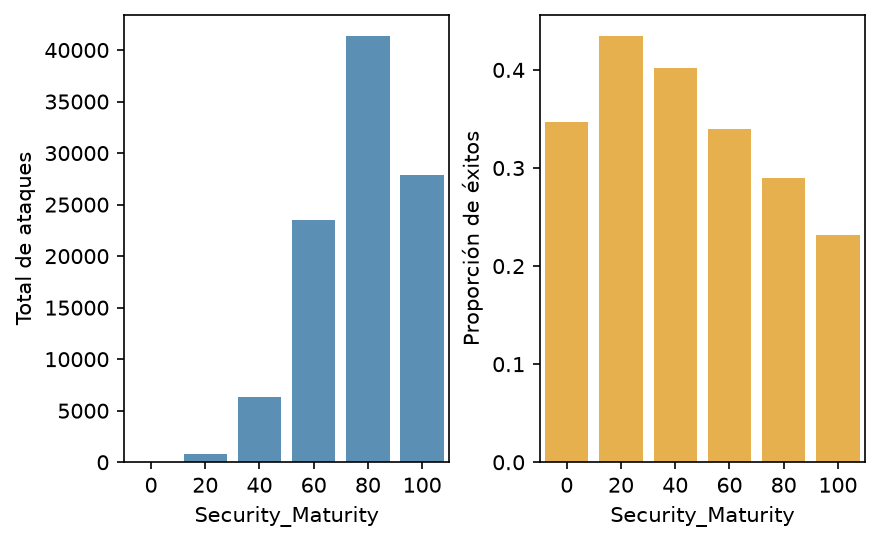

In [12]:
fig, axes = plt.subplots(1,2 ,figsize=(5.75, 3.5), layout="constrained")

sns.barplot(data = madurez, x = "Security_Maturity", y = "Total_de_ataques", alpha = 0.8, ax = axes[0])
sns.barplot(data = madurez, x = "Security_Maturity", y = "Proporcion_de_exitos",
            color = "orange", alpha = 0.8, ax = axes[1])
axes[0].set_ylabel("Total de ataques")
axes[1].set_ylabel("Proporción de éxitos")

Esta tabla muestra, para cada nivel de madurez de seguridad (`Security_Maturity`, 0-20-40-60-80-100), cuántos ataques recibieron las empresas y qué proporción de ellos tuvo éxito.

En la columna de proporción y en el gráfico se observa lo esperado, a medida que aumenta la madurez de la empresa en temas de seguridad, el porcentaje de ataques en su contra disminuye, estableciendo una relación negativa. 

La categoría de `Security_Maturity` igual a 0, probablemente no cumpla con la relación por la baja cantidad de observaciones (49).

### ¿Un ataque más complejo realiza más daño?

<Axes: xlabel='Financial_Loss_USD', ylabel='Density'>

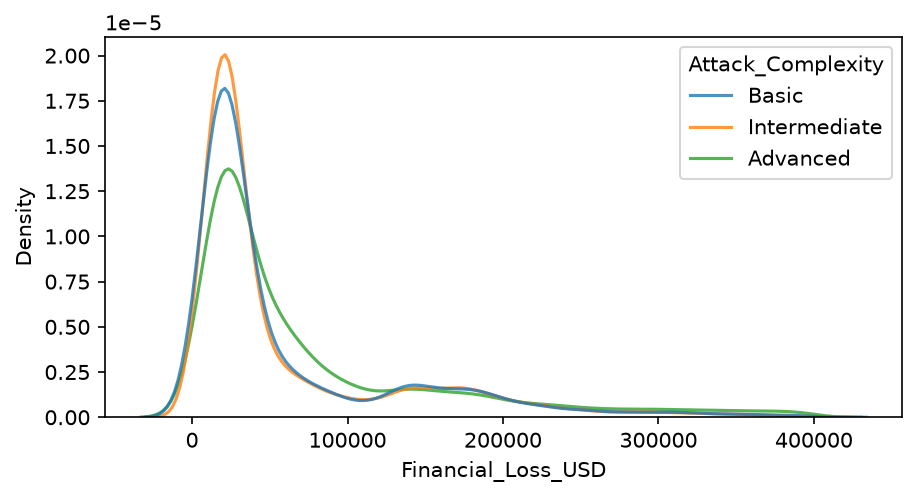

In [13]:
complejidad = ["Basic", "Intermediate", "Advanced"]

fig, ax = plt.subplots(figsize=(6, 3.2), layout="constrained")
sns.kdeplot(data = df[df["Financial_Loss_USD"] < 400000],
            x = "Financial_Loss_USD",
            hue = "Attack_Complexity", hue_order=complejidad,
            ax=ax, alpha = 0.8, common_norm=False)



In [14]:
df[df["Financial_Loss_USD"] > 400000]["Attack_Complexity"].value_counts()

Attack_Complexity
Advanced        1207
Intermediate     416
Basic            139
Name: count, dtype: int64

La variable `Attack_Complexity` categoriza cada ataque por su nivel de complejidad, en basica, intermedia y avanzada.

Para el gráfico se filtró `Financial_Loss_USD` en valores menores a 400000 para que se puedan visualizar mejor las curvas y complementamos con una tabla que cuenta la frecuencia de cada categoría, cuando `Financial_Loss_USD` es mayor a 400000. 

Observamos en el gráfico de densidad de `Financial_Loss_USD` que las categorías basic e intermediate, tienen una distribución casi idéntica, con casi todos sus datos antes de los 100000 USD, y un leve aumento de la densidad sobre los 150000. A diferencia de la categoría advanced, donde su densidad en los primeros valores es mucho menor, y en la tabla podemos ver que los datos filtrados del gráfico, corresponden en su gran mayoría a esta categoría.

Entonces, podríamos concluir que si un ataque tiene un muy alto costo, es probable que haya sido muy complejo.

### ¿Capacitar a los empleados disminuye el riesgo?

<positron-console-cell-15>:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.


[Text(0.5, 0, '¿Los empleados fueron capacitados en ciberseguridad?'),
 Text(0, 0.5, 'Riesgo interno')]

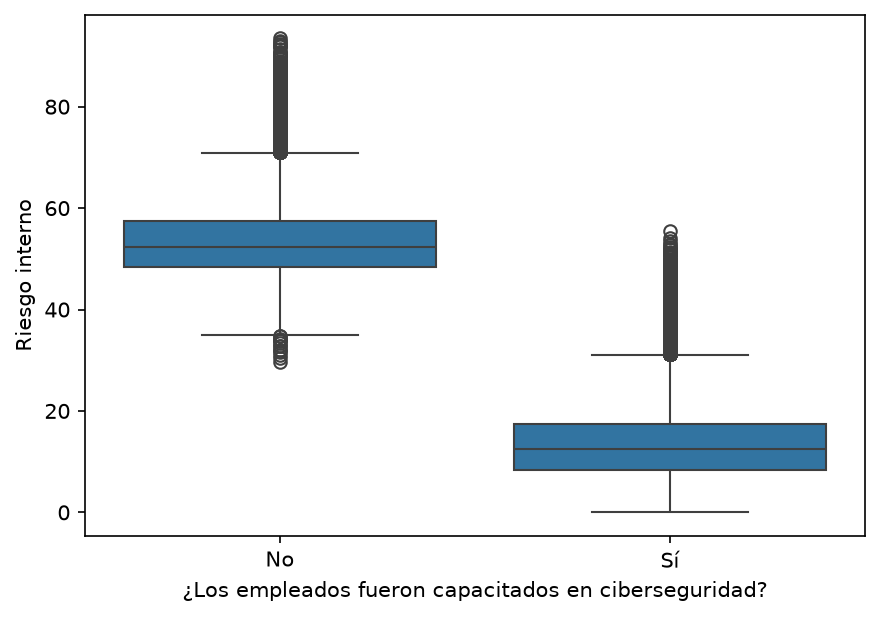

In [15]:
fig, ax = plt.subplots(figsize=(5.75, 4), layout="constrained")
sns.boxplot(data = df,
 y = "Insider_Risk",
 x = "Security_Training", ax=ax)
ax.set_xticklabels(["No", "Sí"])
ax.set(xlabel ="¿Los empleados fueron capacitados en ciberseguridad?",
        ylabel = "Riesgo interno")

La variable `Insider_Risk` mide entre 0 y 100 el riesgo de ataques por causas internas (empleados descuidados o malintencionados).

El diagrama de caja nos muestra la distribución del riesgo interno para las empresas, separandolas entre aquellas que si capacitaron en ciberseguridad a sus empleados y aquellas que no lo hicieron.

Vemos una clara diferencia entre estas empresas, donde la mediana para las empresas que capacitaron es menor a 20, y las que no es mayor a 50, y ambos diagramas con cajas con poco desvío, y no logran superponerse.Aunque debemos notar que ambas categorías tienan una gran cantidad de outliers.

Si bien esta relación parece bastante notoria, en la realidad la variable del riesgo interno es muy díficil de calcular.

### ¿El tamaño del equipo de SOC influye en posibles ataques?

In [16]:
df["perc_SOC"] = 100*df["SOC_Team_Size"] / df["Employee_Count"]
df["cat_SOC"] = df['perc_SOC'].case_when(caselist=[
    (df["perc_SOC"] <= df["perc_SOC"].quantile(0.25), "Bajo"),
    (df["perc_SOC"] <= df["perc_SOC"].quantile(0.50), "Medio"),
    (df["perc_SOC"] <= df["perc_SOC"].quantile(0.75), "Alto"),
    (df["perc_SOC"] > df["perc_SOC"].quantile(0.75), "Muy Alto")
])

(df
.groupby('cat_SOC')
.agg(Total_de_casos = ('Attack_Success', 'size'),
    Cantidad_de_exitos = ('Attack_Success', 'sum'))
.assign(Proporcion_de_exitos = lambda x: x['Cantidad_de_exitos'] / x['Total_de_casos'])
.loc[["Bajo", "Medio", "Alto", "Muy Alto"]]
)

,Total_de_casos,Cantidad_de_exitos,Proporcion_de_exitos
cat_SOC,,,
Bajo,25036,7395,0.295375
Medio,25046,7334,0.292821
Alto,24943,7394,0.296436
Muy Alto,24975,7283,0.291612


El SOC (Security Operations Center) es el equipo que monitorea y responde a amenazas. Utilizamos la proporción de empleados que formar parte del SOC y clasificamos cada empresa en cuatro categorías según sus cuartiles: Bajo, Medio, Alto y Muy Alto.

En los resultados de la tabla vemos que, al contrario de lo que único quizás podría intuir, no hay ninguna relación entre el tamaño del equipo de SOC y la cantidad de ataques recibidos por la empresa que fueron éxitosos, pues la proporción de éxito del ataque para cada grupo, es practicamente igual que la proporción de todas las observaciones.

### ¿Quienes tienen mayor puntuación en la auditoria de ciberseguridad reciben menos ataques?

<Axes: xlabel='Security_Audit_Score', ylabel='Density'>

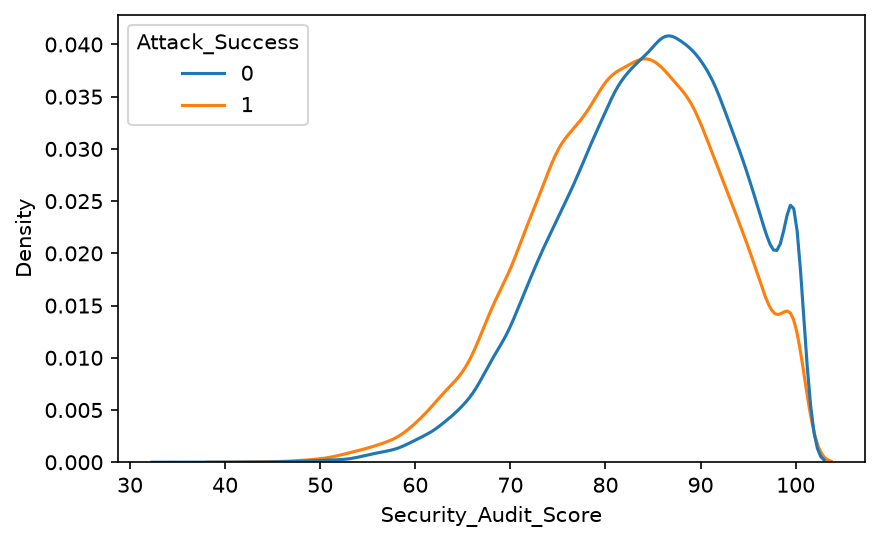

In [17]:
fig, ax = plt.subplots(figsize=(5.75, 3.5), layout="constrained")
sns.kdeplot(data = df,
            x = "Security_Audit_Score", hue = "Attack_Success",
            common_norm=False, ax=ax)

`Security_Audit_Score` es la puntuación de la empresa en auditoría de ciberseguridad (0 a 100). 

El gráfico muestra la densidad de esta variable, separada por `Attack_Success`, donde cada curva tiene área igual a uno, para que sean comparables y no afecte el desbalance de los datos.

Observamos que ambas curvas tiene una forma muy parecida, con una asimetría hacia la izquierda, pero con dos pequeñas diferencias. Primeor vemos que la curva en los casos que falló el ataque está corrida algunos valores hacia la derecha (mejores valores de la auditoría), y que su pico es algo más alto que el de la curva naranja. Si bien estas diferencias logran verse claramente en el gráfico, no son los suficientemente grandes para poder distinguir las observaciones.

### Correlaciónes entre variables númericas

Para finalizar el análisis exploratorio, realizamos un mapa de calor con las correlaciones entre todas las variables númericas

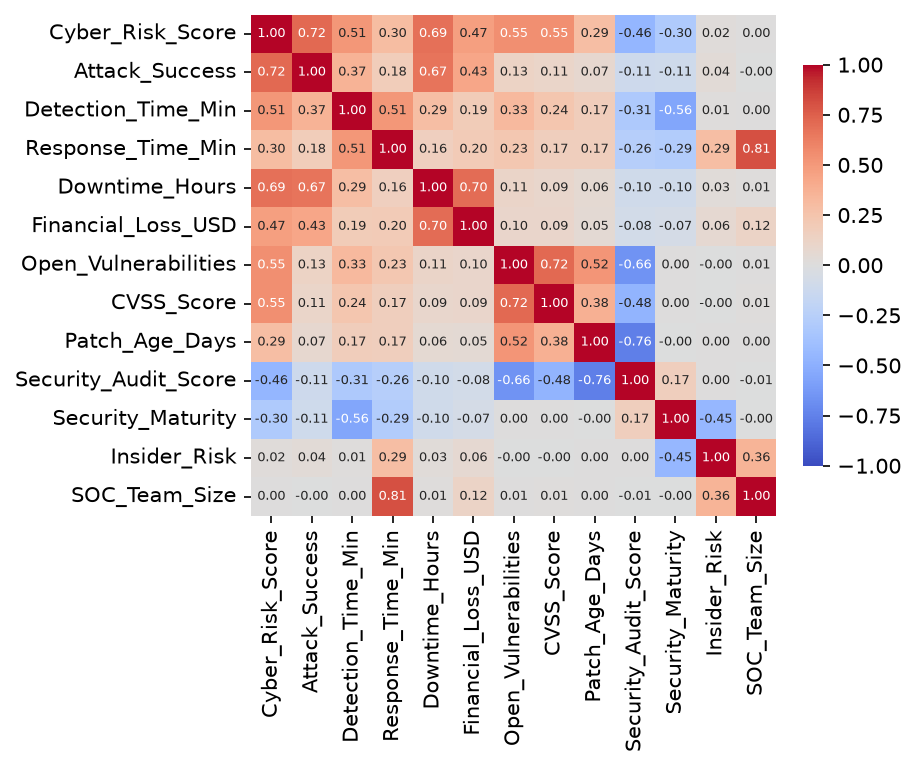

In [18]:
vars_corr = ["Cyber_Risk_Score", "Attack_Success", "Detection_Time_Min", "Response_Time_Min",
             "Downtime_Hours", "Financial_Loss_USD", "Open_Vulnerabilities", "CVSS_Score",
             "Patch_Age_Days", "Security_Audit_Score", "Security_Maturity", "Insider_Risk", "SOC_Team_Size"]

fig, ax = plt.subplots(figsize=(6, 5), layout="constrained")
sns.heatmap(df[vars_corr].corr(), annot=True, fmt=".2f", annot_kws={"size": 6},
            cmap="coolwarm", center=0, vmin=-1, vmax=1, cbar_kws={"shrink": 0.8}, ax=ax)
plt.show()

En este heatmap podemos confirmar relaciones que habíamos analizado y encontrar algunas inesperadas. 

Por ejemplo, vemos que si sucedió el ataque y el riesgo tienen una correlación de 0.72, que se observó en las densidades.

El principal descubrimiento es que `SOC_Team_Size` y `Response_Time_Min` son las variables más correlacionadas, pero de manera positiva, es decir, a mayor valor de una variable, mayor valor de la otra, algo bastante contraintuitivo.

Otras variables muy correlacionadas son `Patch_Age_Days` y `Security_Audit_Score`. Con una correlación de -0.76, demuestra que es razonable, cuanto menor la cantidad de días de la última aplicación del parche de seguridad, la empresa tiene una mejor auditoría en seguridad.

# Modelado

En esta sección realizaremos dos modelos de machine learning:

1- Clasificación: Predecir si el ataque tuvo éxito, `Attack_Success`, con un árbol de decisión

2- Regresión: Predecir el nivel de riesgo del ataque, `Cyber_Risk_Score`, a través de un bosque aleatorio (random forest)

Sabemos que de las 50 variables, muchas caracterizan las consecuencias del ataque, que se conocen una vez que el ataque sucedió. Por ende, para nuestros modelos de predicción, utilizar estas variables no sería lo más adecuado pues, por ejemplo, si queremos saber si un ataque tuvo éxito, y miramos la variable que mide la pérdidas económicas, está claro que si el valor es alto, el ataque sucedió. Lo más interesante sería predecir estas variables de interés a través de aquellas columnas que caracterizan a la empresa, en aspectos generales y en tanto a la defensa ante ataques, y que nos describen un contexto antes de que suceda cualquier ataque. Asumimos que el ataque 'va a suceder' pero no sabemos como, y queremos predecir que tan factible es que suceda o el riesgo que podría tener.

Para ambos modelos, utilizamos el 75% de los datos para entrenarlo, y el restante 25% para testearlo.

### 1. Clasificar `Attack_Success` - Árbol de decisión

A términos generales, un árbol de decisión divide y clasifica los datos a través de diferentes preguntas, sobre los valores que toman las variables. En cada pregunta divide en dos grupos, y a ellos los divide en otros dos con otra pregunta. Así sucesivamente hasta clasificar cada observación en una de las dos categorías de la variable a predecir.

Las columnas que utilizamos para entrenar el modelo, son las que clasificamos en el comienzo como características de la empresa, seguridad ante ataques, y posibles vulnerabilidades. Estas variables son iguales para cada posible ataque que podría recibir una empresa.

Parámetros utilizados en el árbol:

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

# variables que describen a la empresa
desc_empresa = ["Industry", "Country", "Company_Size", "Employee_Count",
          "Firewall", "MFA", "EDR", "IDS", "Security_Training", "Password_Policy",
          "Security_Maturity", "SOC_Team_Size", "Security_Audit_Score", "Compliance",
          "CVSS_Score", "Patch_Age_Days", "Open_Vulnerabilities", "Internet_Exposed",
          "Vendor_Count", "ThirdParty_Risk", "Insider_Risk"]

X_tree = pd.get_dummies(df[desc_empresa])

y_tree = df["Attack_Success"]
X_tree_train, X_tree_test, y_tree_train, y_tree_test = train_test_split(
X_tree, y_tree, test_size=0.25, random_state=123, stratify=y_tree
)

arbol = DecisionTreeClassifier(max_depth= 5, random_state= 123)
arbol.fit(X_tree_train, y_tree_train)
arbol.get_params()


{'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': 5,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'random_state': 123,
 'splitter': 'best'}

Todos los parámetros tienen su valor por defecto, salvo 'max_depth', la profundidad del árbol, que se le asigno un valor pequeño, únicamente para poder visualizar las decisiones que toma el árbol gráficamente, no por la búsqueda de un mejor resultado.

Gráfico del árbol de decisión:

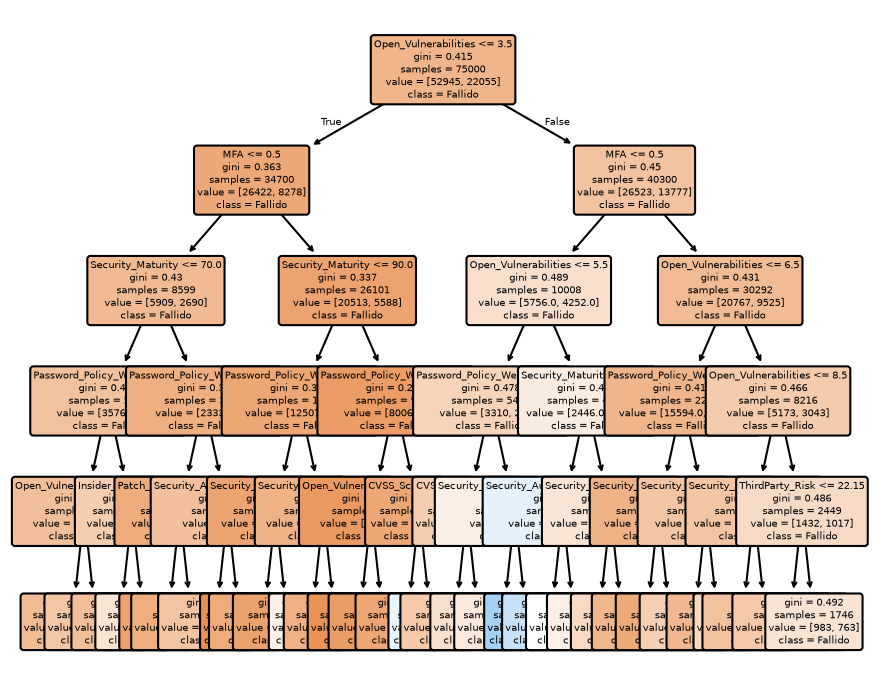

In [20]:
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(5.75, 4.5), layout="constrained")
plot_tree(arbol, feature_names=X_tree.columns, class_names=["Fallido", "Exitoso"],
           filled=True, rounded=True, fontsize = 5,ax=ax)
plt.show()

Si bien no logra visualizarse perfectamente, podemos observar a rasgos generales como se fue creando el árbol. Por ejemplo, la primera decisión que toma es preguntar si `Open_Vulnerabilities` es menor o igual a 3.5. A todas las observaciones cuya respuesta sea verdadera, las 'envía' al grupo de la izquierda, y al resto a la derecha.

Podemos observar, que cada hoja se pinta de naranja si a ese grupo de observaciones lo clasifica como ataque fallido, y de celeste si lo clasifica como ataque éxitoso. Vemos que la gran mayoría de las hojas son naranjas, esto se debe al desbalance en los datos de `Attack_Success`.

Matriz de confusión del árbol sobre los datos de test:

In [21]:
from sklearn.metrics import confusion_matrix

confusion_matrix(y_tree_test, arbol.predict(X_tree_test))

array([[17477,   172],
       [ 7189,   162]])

Las filas indican los valores reales y las columnas las predicciones. El valor en la posición (0,0) representa la cantidad de observaciones donde el valor real era 0 (no éxito) y se predijo 0. 

Entonces el árbol predijo, en la 25000 observaciones de test, correctamente 17477 ataques como fallidos, y 162 como exitosos. Cometió error en 172 observaciones clasificandolas como éxito, y en verdad era fallido; y en 7189 clasificando como fallido, y era éxito.

Métricas de evaluación:

In [22]:
from sklearn.metrics import classification_report

print(classification_report(y_tree_test, arbol.predict(X_tree_test)))

              precision    recall  f1-score   support

           0       0.71      0.99      0.83     17649
           1       0.49      0.02      0.04      7351

    accuracy                           0.71     25000
   macro avg       0.60      0.51      0.43     25000
weighted avg       0.64      0.71      0.60     25000



- Accuracy general (0,71): proporción de aciertos totales. Parece aceptable mirandolo por si solo, pero un árbol que solo predice ataque fallido, tiene 70.6% de precisión.
- Recall de la clase éxito (0,02): De todos los ataques exitosos, solo predijo 2% correctamente.
- El F1 de la clase éxito (0,04): muestra lo mismo que antes, al modeo le cuesta mucho detectar correctamente ataques que tuvieron éxito.

Conclusión, el árbol realizado no es bueno clasificando ataques, pues tiende a clasificar prácticamente a todas las observaciones como fallido. Este error se debe en gran parte al desbalance de los datos, y a que no hay fuertes relaciones entre el conjuntos de estas variables y el éxito o no de un ataque.

### 2. Predecir `Cyber_Risk_Score` - Bosque aleatorio de regresión

En este caso, la variable a predecir es continua, por lo que se denomina un problema de regresión. Se intentará predecir un valor concreto de la variable.

A grandes rasgos, un random forest, es el conjunto de muchos árboles, donde cada uno se entrena y la predicción final es el promedio de las predicciones de todos los árboles. La ventaja está en que al ser más arboles, el modelo es más robusto, pero se pierde interpretabilidad, pues ya no podemos ver las decisiones que toma el modelo.

En este caso, vamos a utilizar las mismas variables que en el árbol, y le agreamos las que describen el comienzo del ataque. Agregamos las posibles formas que tiene el atacante de introducirse en la empresa. 

In [23]:
from sklearn.model_selection import train_test_split

# variables que describen el inicio del ataque
desc_ataque = ["Attack_Vector", "Threat_Actor", "Attack_Complexity", "Zero_Day",
          "Hour", "DayOfWeek", "Month", "Business_Hours", "Weekend", "Phishing_Click"]

X_rf = pd.get_dummies(df[desc_empresa + desc_ataque])
y_rf = df["Cyber_Risk_Score"]

X_rf_train, X_rf_test, y_rf_train, y_rf_test = train_test_split(
X_rf, y_rf, test_size=0.25, random_state=123
)

Los hiperparámetros del bosque se elegieron mediante la validación cruzada, que nos permite evaluar distintas combinaciones de hiperparámetros, pero sin utilizar los datos de test.

Se simularon las siguientes combinaciones, con un CV = 4:

"max_depth": [5, 10, None] -
"max_features": [0.2, 0.5, 1.0]

En las pruebas de la validación cruzada, se realizaron 100 árboles, pero el bosque final, con la mejor combinación de hiperparámetros, se realizó con 250.

Resultado de la validación cruzada:

In [24]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV

grilla = GridSearchCV(
    RandomForestRegressor(n_estimators=100, random_state=123),
    param_grid={"max_depth": [5, 10, None],
                "max_features": [0.2, 0.5, 1.0]},
    cv=4,
    n_jobs = -1
)

grilla.fit(X_rf_train, y_rf_train)
grilla.best_params_, grilla.best_score_.round(3)

({'max_depth': 10, 'max_features': 0.5}, np.float64(0.546))

Ahora entrenamos un bosque con esos valores de 250 árboles.

Métricas de evaluación sobre datos de test:

In [25]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

rf = RandomForestRegressor(n_estimators = 250, max_depth= 10, max_features = 0.5, random_state=123)
rf.fit(X_rf_train, y_rf_train)

pd.Series({
"MAE": mean_absolute_error(y_rf_test, rf.predict(X_rf_test)),
"RMSE": root_mean_squared_error(y_rf_test, rf.predict(X_rf_test)),
"R2": r2_score(y_rf_test, rf.predict(X_rf_test)),
}).round(2)

MAE     10.69
RMSE    12.70
R2       0.55
dtype: float64

- MAE: El promedio de los errores en valor absoluto es de 10.7.
- RMSE: El promedio de los errores al cuadrado es de 12.70. Muy parecido al MAE, castigando más los errores grandes.
- R2: el modelo explica el 55% de la variabilidad del riesgo.

Conclusión, el modelo no termina de ser del todo bueno, pues hay un 45% del riesgo que no logra explicar, y en una escala del 1 al 100, un error mayor a 10 puntos en promedio, no es para nada menor. Demuestra que las variabls utilizadas no tienen una fuerte relación con el riesgo del ataque.

Importancia de las variables para predecir (solo las que superan 0.01):

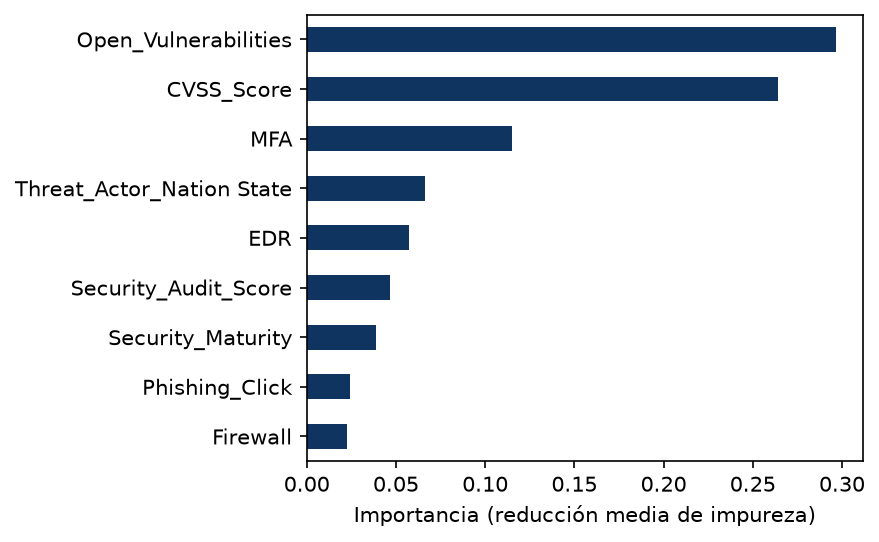

In [26]:
importancias = pd.Series(rf.feature_importances_, index=X_rf.columns).sort_values()
importancias = importancias[importancias > 0.01]

fig, ax = plt.subplots(figsize=(5.75, 3.5), layout="constrained")
importancias.plot.barh(color="#0f3460", ax=ax)
ax.set(xlabel="Importancia (reducción media de impureza)", ylabel="")
plt.show()

En términos generales, la importancia mide cuanto contribuye la variable en el modelo. 

Vemos que hay dos variables que predominan claramente. `Open_Vulnerabilities` cuenta el número de vulnerabilidades de la empresa sin resolver, y `CVSS_Score` es la puntuación entre 1 y 10 del Sistema Común de Puntuación de Vulnerabilidades, que manifiesta que tan vulnerable es el sistema de seguridad de la empresa.

# Comentarios finales:

En este proyecto buscábamos analizar y entender las caracterísitcas de los ciberataques, y las razones por las cuales hace que un ciberataque tenga éxito y qué factores elevan su nivel de riesgo, mirando tanto cómo se lleva a cabo el ataque como la situación de la empresa que lo recibe. 

Las principales conclusiones que podemos extraer del analisis exploratorio, son que en general se cumplen las relaciones esperadas. Por ejemplo, que a mayor madurez en seguridad, menor cantidad de ataques, o que a más comlpejo un ataque, mayores consecuencias monetarias contrae. Aunque si hubo algunas excepciones, como que el porcentaje de trabajodores en el equipo de SOC no influye en la cantidad de ataques con éxito. 

En cuanto a los modelos, concluimos que no tuvieron un gran rendimiento. Las causas podrían ser los datos desbalanceados, que las variables del dataset no son suficentes, o que realmente es muy complejo predecir si un ataque sucederá solamente observando a la empresa, pues los ciberataques son incidentes bastante impredecibles y que se pueden realizar de muchas maneras.

Como posible línea futura de trabajo, sin dudas que el principal aspecto a mejorar son los datos. Trabajar con datos reales sería mucho más fructífero y nos permitiría obtener conclusiones reales sobre los ciberataques. También sería interesante utilizar otros modelos de machine learning, o realizar un análisis más exhaustivos en caunto a los parámetros de los modelos realizados, para intentar obtener mejores resultados.



# Referencias:


- Link del dataset: [Cyber Attack Detection and risk prediction dataset](https://www.kaggle.com/datasets/aiexplorer77/cyber-attack-detection-and-risk-prediction-dataset)

- En el repositorio de proyecto se encuentra un archivo pdf que contiene la definición de cada una de las variables del dataset.